# SportSnap Challenge — Baseline
**Image classification · Transfer learning**

A photo lands on your desk. No caption, no context — just someone mid-motion. What sport is it?

Easy for a human. Can you build a model that does it across **100 sports**, from basketball and tennis
to sepak takraw and disc golf?

| | |
|---|---|
| **Train** | ~14,000 labeled images (`train/` + `train.csv`: `image_id,label`) |
| **Test** | 500 unlabeled images (`test/` + `test.csv`: `image_id`) |
| **Classes** | 100 sports |
| **Metric** | **Top-1 accuracy** |
| **Submission** | `id,label` — `id` is the test `image_id`, `label` is the class **index** (0–99, classes sorted alphabetically) |

This baseline trains only a small classifier head on top of a **frozen** pretrained MobileNetV2.
It is a solid start, but far from the ceiling. How far can you push it?

A GPU is strongly recommended (Kaggle: *Settings → Accelerator → GPU*).

### Notebook structure
1. Setup
2. Explore the data
3. Prepare the data
4. Build the model
5. Train
6. Training curves
7. Validation: top-1 / top-5 accuracy
8. Per-class accuracy
9. Most confused sports
10. Generate submission
11. Test-set evaluation
12. Ideas to improve

## 1. Setup

In [1]:
import os
import warnings
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

warnings.filterwarnings('ignore')

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():   # Apple silicon
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f'Using device: {device}')

# Works on Kaggle and locally (put the competition files in ./data)
COMPETITION = 'sports-master'
CANDIDATES  = [Path(f'/kaggle/input/competitions/{COMPETITION}'), Path(f'/kaggle/input/{COMPETITION}'), Path('data')]
DATA_DIR    = next(p for p in CANDIDATES if p.exists())
print('Data directory:', DATA_DIR, '→', sorted(os.listdir(DATA_DIR)))

Using device: mps
Data directory: data → ['test', 'test.csv', 'train', 'train.csv']


## 2. Explore the Data

In [2]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

train_csv = pd.read_csv(DATA_DIR / 'train.csv')
train_csv = train_csv[train_csv['image_id'].map(lambda x: Path(x).suffix.lower() in IMAGE_EXTS)].reset_index(drop=True)

print(f'Training images       : {len(train_csv)}')
print(f'Number of classes     : {train_csv["label"].nunique()}')
print(f'Images per class (avg): {len(train_csv) / train_csv["label"].nunique():.0f}')
train_csv.head()

Training images       : 13992
Number of classes     : 100
Images per class (avg): 140


,image_id,label
0,air hockey_001.jpg,air hockey
1,air hockey_002.jpg,air hockey
2,air hockey_003.jpg,air hockey
3,air hockey_004.jpg,air hockey
4,air hockey_005.jpg,air hockey


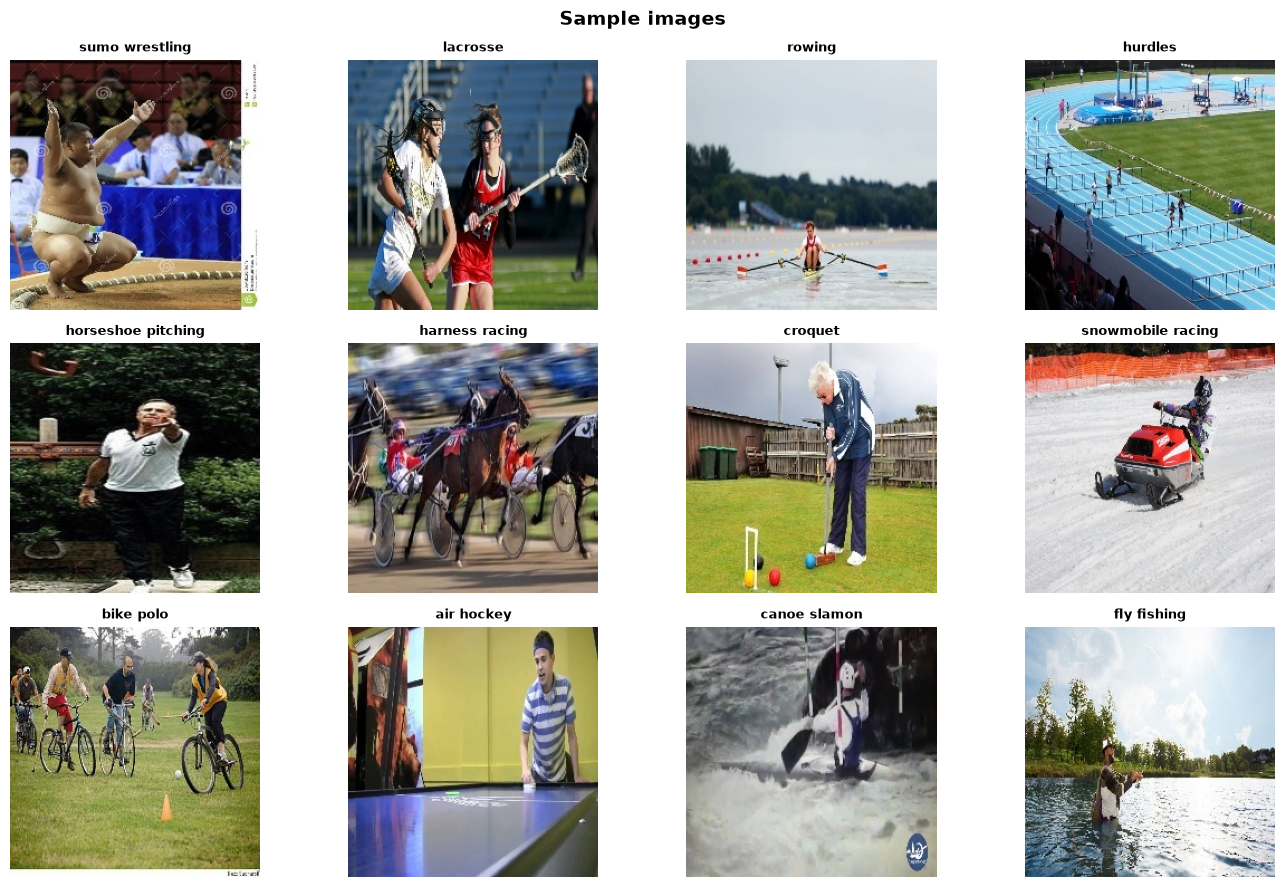

In [3]:
sample = train_csv.groupby('label').first().sample(12, random_state=SEED).reset_index()
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, (_, row) in zip(axes.flatten(), sample.iterrows()):
    ax.imshow(Image.open(DATA_DIR / 'train' / row['image_id']))
    ax.set_title(row['label'], fontsize=9, fontweight='bold')
    ax.axis('off')
plt.suptitle('Sample images', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Prepare the Data

In [4]:
class SportsDataset(Dataset):
    def __init__(self, df, img_dir, label_map, transform=None):
        self.df        = df.reset_index(drop=True)
        self.img_dir   = img_dir
        self.label_map = label_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(self.img_dir / row['image_id']).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.label_map[row['label']]


class SportsTestDataset(Dataset):
    def __init__(self, csv_path, img_dir, transform=None):
        self.df        = pd.read_csv(csv_path)
        self.img_dir   = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image_id = self.df.iloc[idx]['image_id']
        img      = Image.open(self.img_dir / image_id).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, image_id


IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

classes      = sorted(train_csv['label'].unique())
label_map    = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in label_map.items()}

train_df, val_df = train_test_split(train_csv, test_size=0.15, stratify=train_csv['label'], random_state=SEED)

train_dataset = SportsDataset(train_df, DATA_DIR / 'train', label_map, transform=train_transform)
val_dataset   = SportsDataset(val_df,   DATA_DIR / 'train', label_map, transform=eval_transform)
test_dataset  = SportsTestDataset(DATA_DIR / 'test.csv', DATA_DIR / 'test', transform=eval_transform)

BATCH_SIZE   = 32
NUM_WORKERS  = 2 if device.type == 'cuda' else 0   # worker processes can't import notebook classes on macOS
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f'Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}')

Train: 11893 | Val: 2099 | Test: 500


## 4. Build the Model

### How transfer learning works
A pretrained network has two parts:
- **Backbone** — convolutional layers trained on ImageNet that detect edges, textures and shapes.
This is general visual knowledge.
- **Classifier head** — the final layers that map those features to class predictions.

We **freeze** the backbone (`requires_grad = False`), so PyTorch computes no gradients for it and
the optimizer cannot change it. We replace the head with our own (100 sports) and train only that.
It works because the backbone already knows how to *see*; we only teach it the sport-specific part.

In [5]:
class SportSnapNet(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()
        self.backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        for param in self.backbone.parameters():
            param.requires_grad = False
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier[1] = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.backbone(x)


model = SportSnapNet(num_classes=len(classes)).to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f'Trainable parameters: {trainable:,} / {total:,}')

Trainable parameters: 353,636 / 2,577,508


## 5. Train

In [6]:
loss_fn   = nn.CrossEntropyLoss()
optimizer = Adam(model.backbone.classifier.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss   = loss_fn(logits, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / len(loader), correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += loss_fn(logits, labels).item()
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / len(loader), correct / total

In [7]:
NUM_EPOCHS = 4
history = defaultdict(list)

print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}")
print('-' * 55)
for epoch in range(1, NUM_EPOCHS + 1):
    t_loss, t_acc = train_one_epoch(model, train_loader, optimizer)
    v_loss, v_acc = evaluate(model, val_loader)
    scheduler.step(v_loss)
    for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [t_loss, t_acc, v_loss, v_acc]):
        history[k].append(v)
    print(f'{epoch:>6} | {t_loss:>10.4f} | {t_acc:>8.1%} | {v_loss:>8.4f} | {v_acc:>6.1%}')

 Epoch | Train Loss | Train Acc | Val Loss | Val Acc
-------------------------------------------------------


     1 |     3.3221 |    21.1% |   1.6793 |  60.6%


     2 |     2.0402 |    44.2% |   1.1403 |  71.1%


     3 |     1.7290 |    51.3% |   0.9643 |  74.1%


     4 |     1.5964 |    54.6% |   0.8848 |  75.8%


## 6. Training Curves

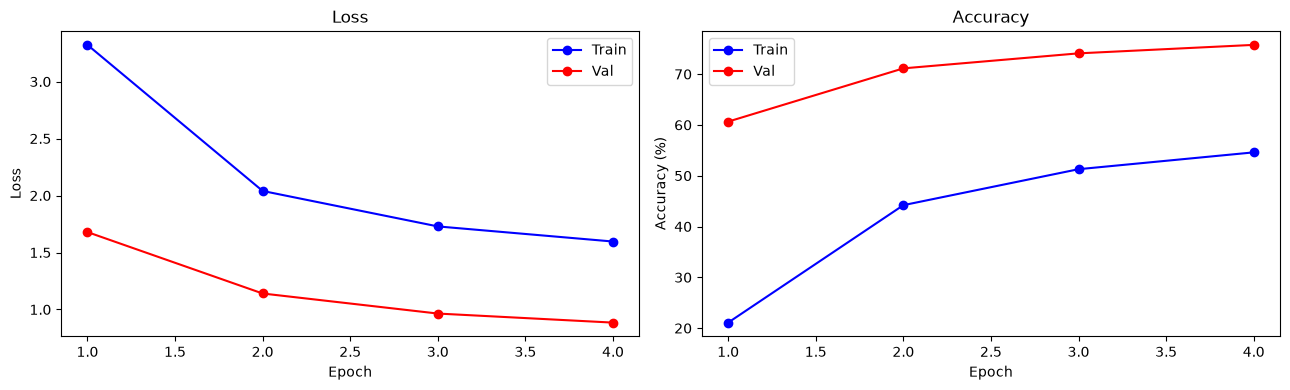

In [8]:
epochs = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(epochs, history['train_loss'], 'b-o', label='Train')
ax1.plot(epochs, history['val_loss'],   'r-o', label='Val')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.set_title('Loss'); ax1.legend()

ax2.plot(epochs, [a * 100 for a in history['train_acc']], 'b-o', label='Train')
ax2.plot(epochs, [a * 100 for a in history['val_acc']],   'r-o', label='Val')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.set_title('Accuracy'); ax2.legend()

plt.tight_layout()
plt.show()

## 7. Validation: Top-1 / Top-5 Accuracy

In [9]:
@torch.no_grad()
def predict_with_top5(model, loader):
    model.eval()
    top1, top5, total = 0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        top1  += (logits.argmax(1) == labels).sum().item()
        top5  += (logits.topk(5, dim=1).indices == labels[:, None]).any(dim=1).sum().item()
        total += labels.size(0)
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return top1 / total, top5 / total, np.array(all_preds), np.array(all_labels)


top1, top5, val_preds, val_labels = predict_with_top5(model, val_loader)
print(f'Val top-1 accuracy: {top1:.1%}')
print(f'Val top-5 accuracy: {top5:.1%}')

Val top-1 accuracy: 75.8%
Val top-5 accuracy: 95.5%


## 8. Per-Class Accuracy

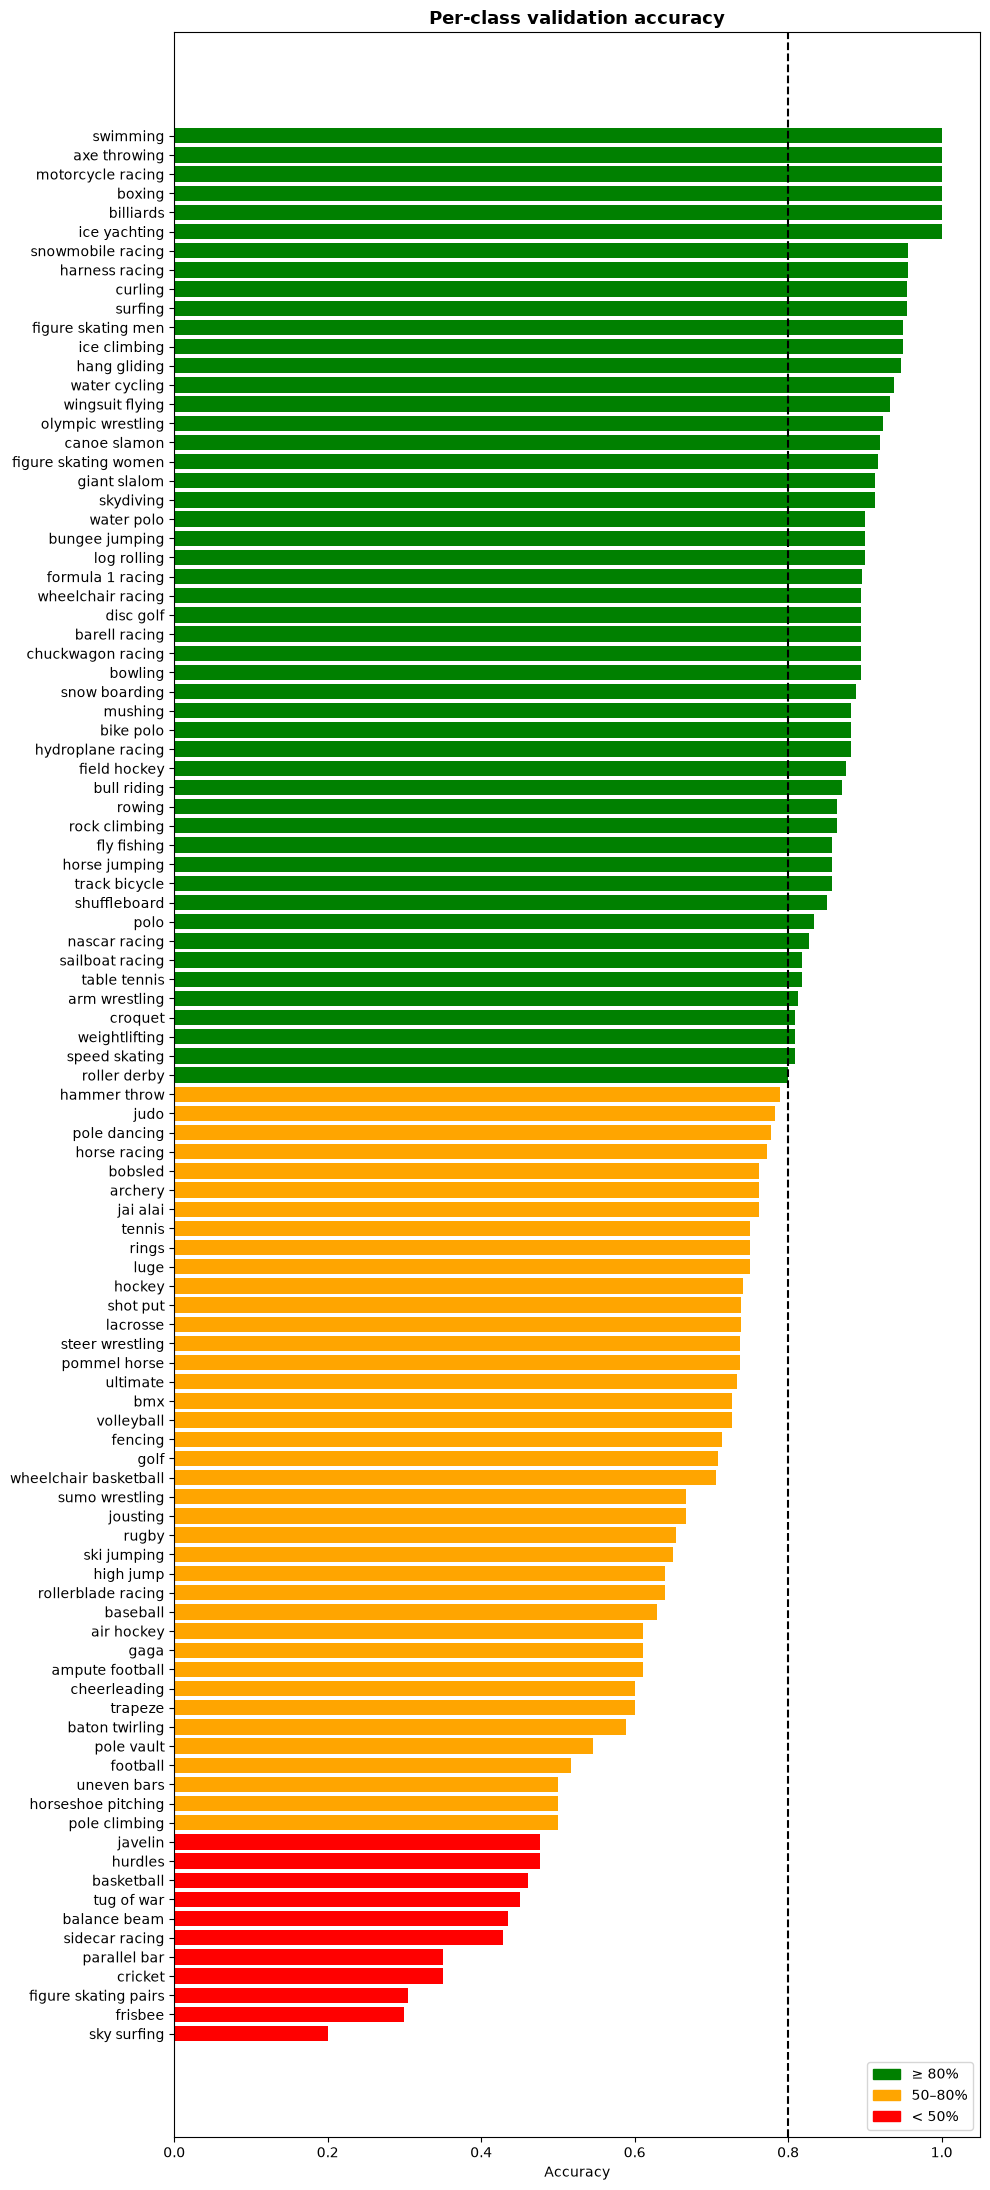

In [10]:
per_class = np.array([(val_preds[val_labels == i] == i).mean() for i in range(len(classes))])
order     = np.argsort(per_class)
colors    = ['green' if a >= 0.8 else 'red' if a < 0.5 else 'orange' for a in per_class[order]]

fig, ax = plt.subplots(figsize=(10, 22))
ax.barh([classes[i] for i in order], per_class[order], color=colors)
ax.axvline(x=0.8, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Accuracy')
ax.set_title('Per-class validation accuracy', fontsize=13, fontweight='bold')
ax.legend(handles=[mpatches.Patch(color='green',  label='≥ 80%'),
                   mpatches.Patch(color='orange', label='50–80%'),
                   mpatches.Patch(color='red',    label='< 50%')], loc='lower right')
plt.tight_layout()
plt.show()

## 9. Most Confused Sports

True                      -> Predicted                  Count
------------------------------------------------------------
sidecar racing            -> motorcycle racing          9
figure skating pairs      -> figure skating women       8
figure skating pairs      -> figure skating men         6
football                  -> lacrosse                   5
luge                      -> bobsled                    4
uneven bars               -> balance beam               4
rugby                     -> lacrosse                   4
ampute football           -> field hockey               4
cricket                   -> croquet                    4
sky surfing               -> skydiving                  3


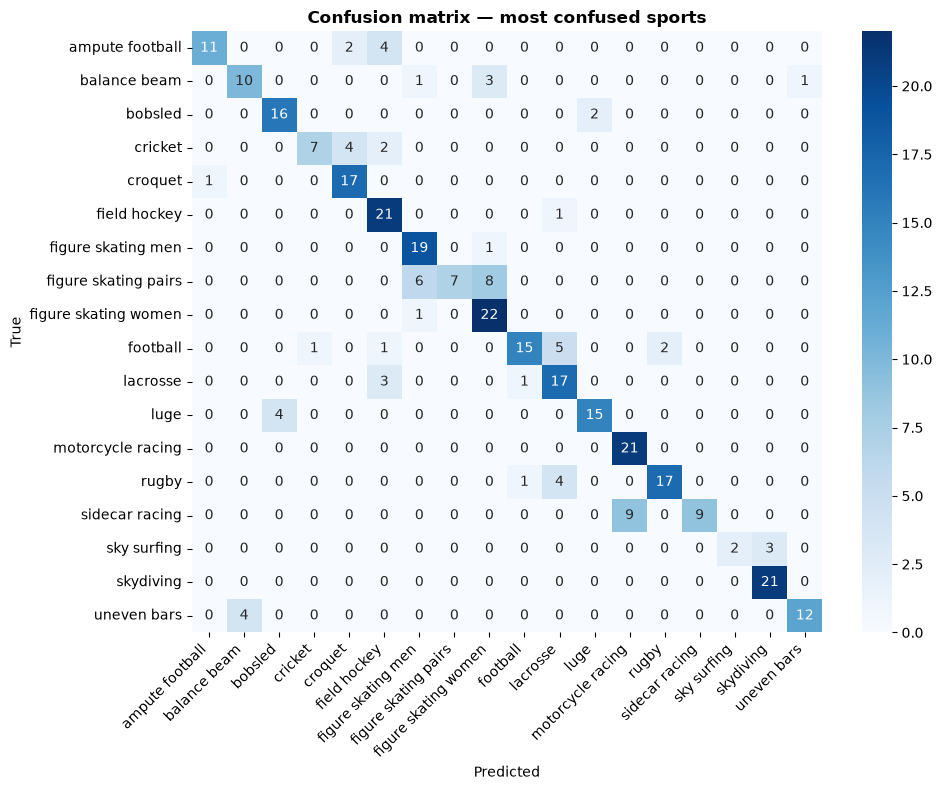

In [11]:
cm = confusion_matrix(val_labels, val_preds, labels=range(len(classes)))
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
top_pairs = [divmod(i, len(classes)) for i in np.argsort(off_diag.ravel())[::-1][:10]]

print(f"{'True':25s} -> {'Predicted':25s}  Count")
print('-' * 60)
for t, p in top_pairs:
    print(f'{classes[t]:25s} -> {classes[p]:25s}  {cm[t, p]}')

confused = sorted({c for pair in top_pairs for c in pair})
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm[np.ix_(confused, confused)], annot=True, fmt='d', cmap='Blues',
            xticklabels=[classes[i] for i in confused], yticklabels=[classes[i] for i in confused], ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion matrix — most confused sports', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 10. Generate Submission

In [12]:
model.eval()
image_ids, predictions = [], []
with torch.no_grad():
    for images, ids in test_loader:
        image_ids.extend(ids)
        predictions.extend(model(images.to(device)).argmax(1).cpu().tolist())

submission = pd.DataFrame({'id': image_ids, 'label': predictions})
submission.to_csv('submission.csv', index=False)

print(f'Saved {len(submission)} predictions to submission.csv')
print(f'Baseline — frozen MobileNetV2, {NUM_EPOCHS} epochs | val top-1 {top1:.2%} | val top-5 {top5:.2%}')
submission.head()

Saved 500 predictions to submission.csv
Baseline — frozen MobileNetV2, 4 epochs | val top-1 75.75% | val top-5 95.47%


,id,label
0,air hockey_1.jpg,0
1,air hockey_2.jpg,0
2,air hockey_3.jpg,0
3,air hockey_4.jpg,11
4,air hockey_5.jpg,15


## 11. Test-Set Evaluation

The test file names contain the true sport (`air hockey_1.jpg` → `air hockey`), so the submission can be
scored locally exactly like the leaderboard does: top-1 accuracy over the 500 test images.

In [13]:
true_labels = submission['id'].str.rsplit('_', n=1).str[0].map(label_map)
assert true_labels.notna().all(), 'Every test file name should start with a known class'

correct  = (submission['label'] == true_labels)
test_acc = correct.mean()
print(f'Test top-1 accuracy: {test_acc:.2%}  ({correct.sum()}/{len(submission)} images)')

per_class_test = correct.groupby(true_labels.map(idx_to_class)).mean().sort_values()
print('\nHardest test classes:')
print(per_class_test.head(10).to_string())

Test top-1 accuracy: 81.20%  (406/500 images)

Hardest test classes:
id
bike polo             0.2
bobsled               0.2
parallel bar          0.2
horseshoe pitching    0.2
sidecar racing        0.2
frisbee               0.2
trapeze               0.4
baseball              0.4
baton twirling        0.4
sky surfing           0.4


## 12. Ideas to Improve

- **Fine-tuning.** After the head converges, unfreeze the backbone (`requires_grad = True`) and keep
training with a very small learning rate (e.g. `1e-5`). Unfreezing too early or with a large learning
rate destroys the pretrained weights (*catastrophic forgetting*).
- Train longer (the curves above have not plateaued).
- A stronger backbone: EfficientNet-B0/B3, ResNet-50, ConvNeXt.
- Stronger augmentation (`RandomResizedCrop`, `TrivialAugmentWide`), label smoothing, a warm-up schedule.
- Test-time augmentation (average predictions over flipped images).